Name: Naveed Alboudwarej 
<br>
USC ID: 8695198359

## 1. Tree-Based Methods

Import packages

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.pyplot import subplots
from ISLP import confusion_table
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV,KFold
from sklearn.metrics import RocCurveDisplay
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

### (a) Download the APS Failure data

In [40]:
train= pd.read_csv("aps_failure_training_set.csv",skiprows= 20,na_values= "na")
test= pd.read_csv("aps_failure_test_set.csv",skiprows= 20,na_values= "na")
train["class"]= train["class"].map({"neg":0,"pos":1})
test["class"]= test["class"].map({"neg":0,"pos":1})
print("Train shape =",train.shape)
print("Test shape =",test.shape)

Train shape = (60000, 171)
Test shape = (16000, 171)


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Common techniques for dealing with missing values are data removal, simple imputation and statistical model-based imputation. Data removal drops the rows or columns that have missing values. Simple imputation fills the missing values with the mean, median or mode of the column. Model-based imputation predicts the missing values from the other variables.

The best choice depends on the amount of missing data and the data type. In this data about 99% of the training rows have at least one missing value and the features are heavily skewed. Therefore, median imputation is the best method here because it keeps all of the rows, it is simple, and the median is less affected by extreme values than the mean. Each set is filled with its own column medians, as the footnote says.

In [3]:
print("Training rows left after dropna =",len(train.dropna()))
print("Test rows left after dropna =",len(test.dropna()))
train= train.fillna(train.median())
test= test.fillna(test.median())

Training rows left after dropna = 591
Test rows left after dropna = 165


#### (ii) Calculate the coefficient of variation

In [4]:
x_train= train.drop(columns= "class")
cv= x_train.std()/x_train.mean()
print(cv)

aa_000      2.450938
ab_000     10.383494
ac_000      2.310241
ad_000    244.322816
ae_000     24.200137
             ...    
ee_007      5.012754
ee_008      3.259079
ee_009      5.691612
ef_000     49.366659
eg_000     42.481747
Length: 170, dtype: float64


The CV varies a lot across the features, for example 2.31 for ac_000, 24.20 for ae_000 and 244.32 for ad_000.

#### (iii) Plot a correlation matrix

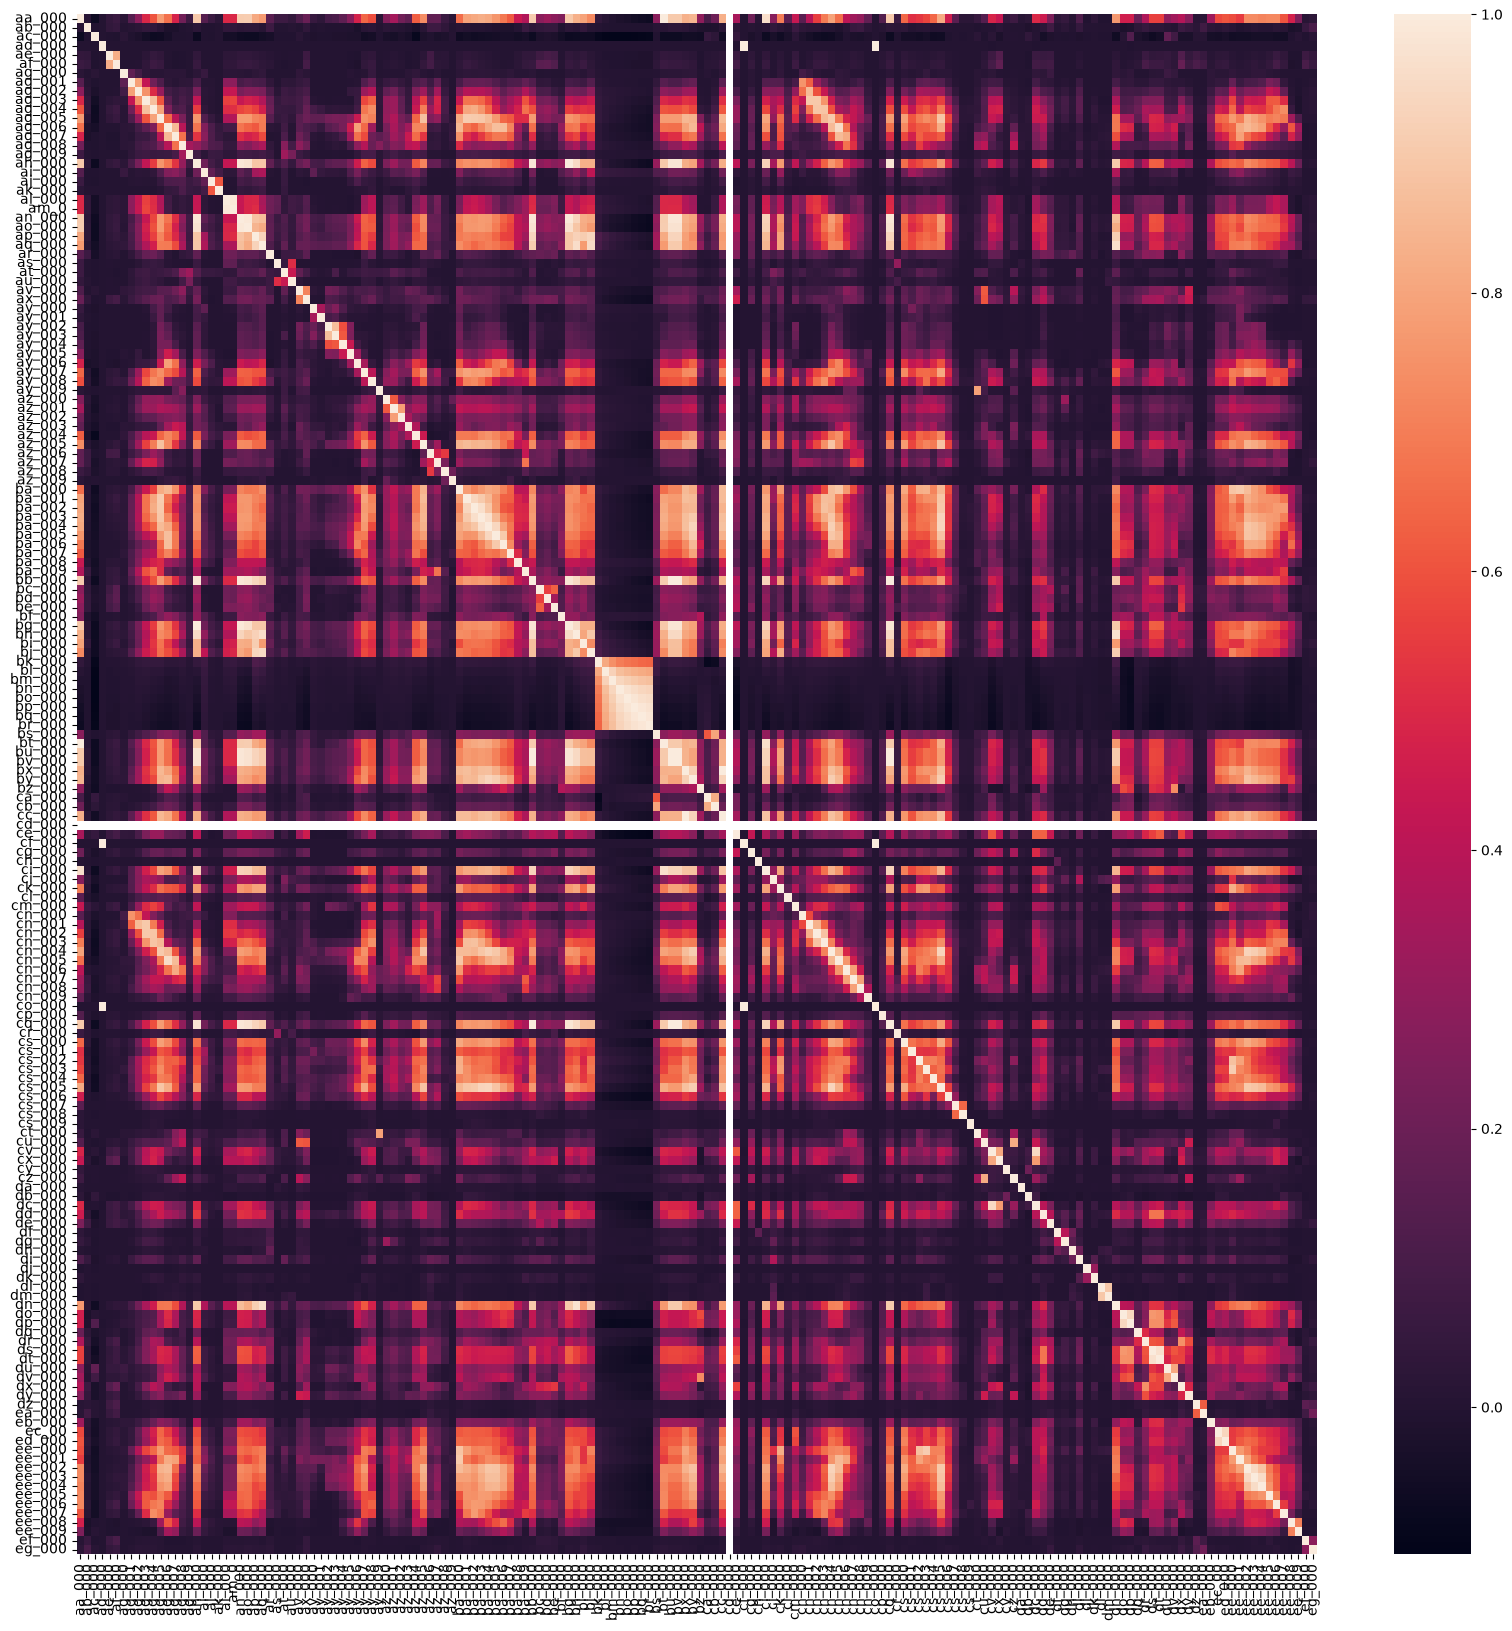

In [27]:
fig,axis= subplots(figsize= (20,20))
sns.heatmap(x_train.corr(),xticklabels= True,yticklabels= True,ax= axis);

Most squares in the heatmap are dark, so most pairs of features have low correlation. There are bright blocks where groups of features are strongly correlated, for example the ba and ee features. The white row and column is cd_000, which is constant, so its correlation is undefined.

#### (iv) Make scatter plots and box plots

Top features per CV = Index(['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000',
       'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000'],
      dtype='object')


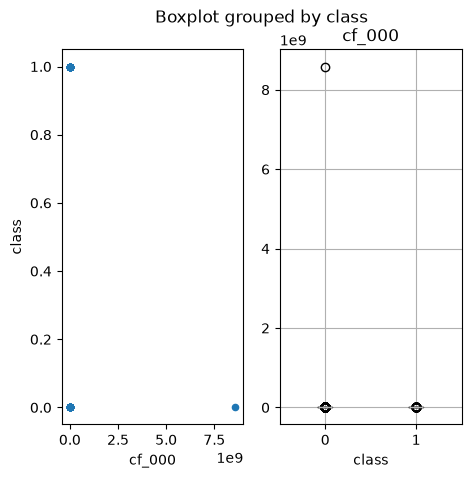

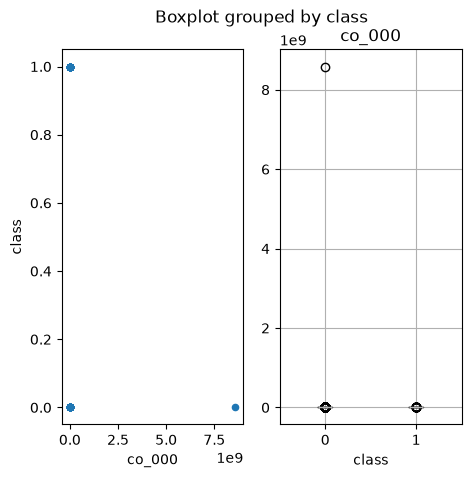

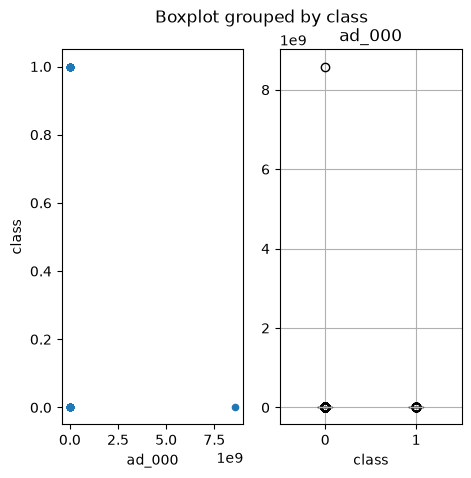

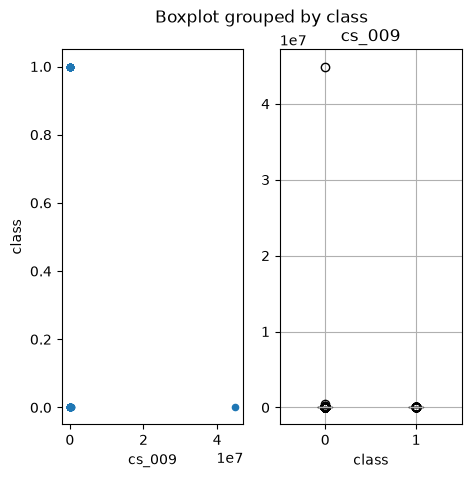

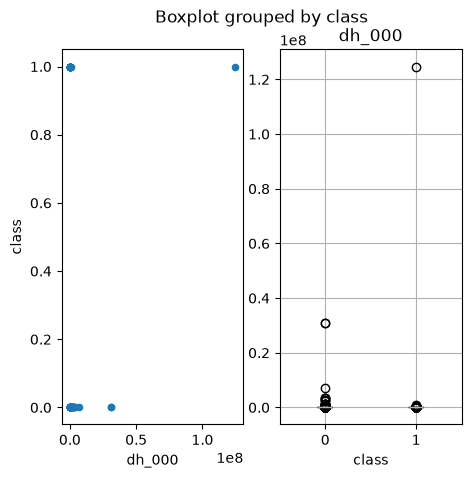

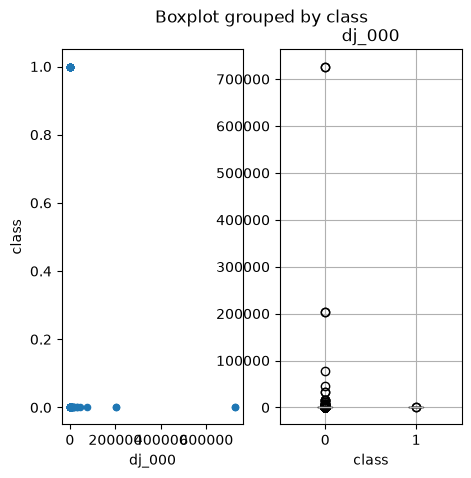

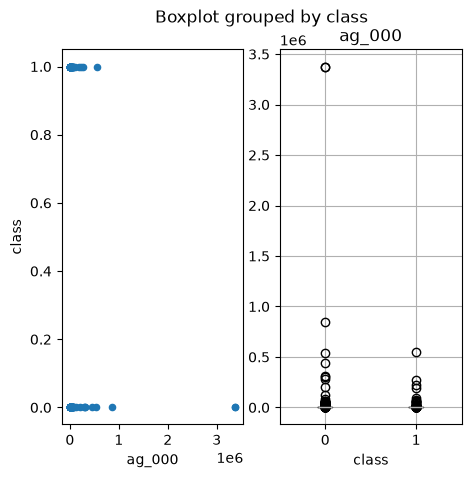

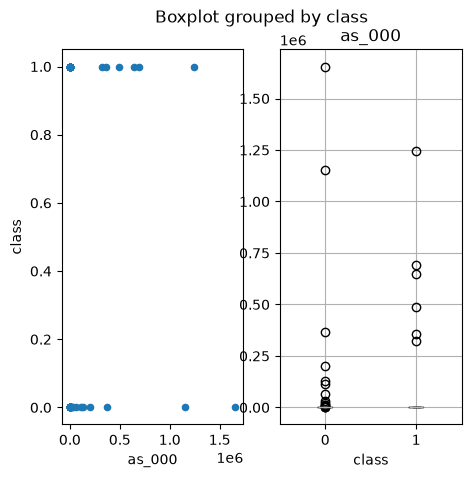

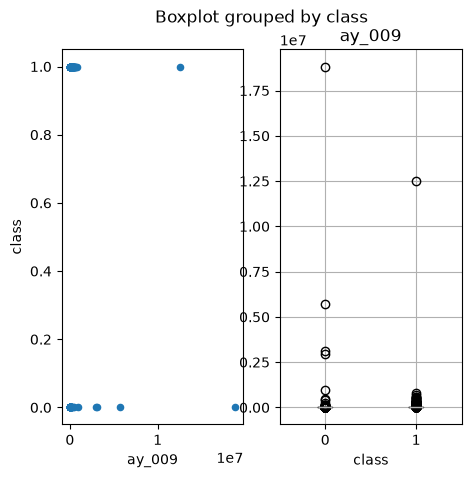

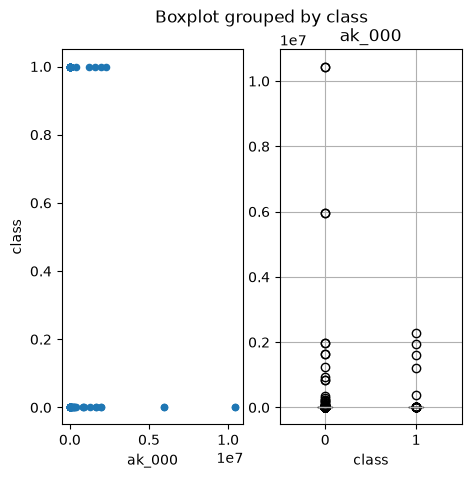

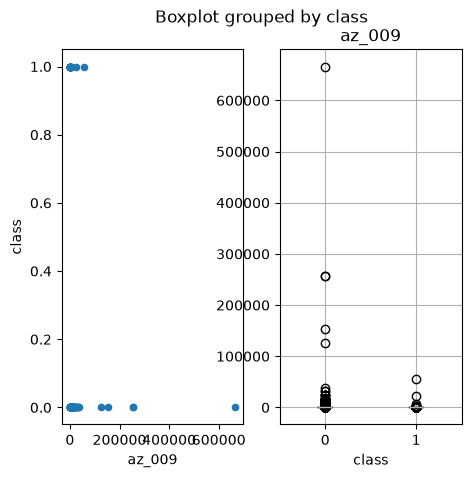

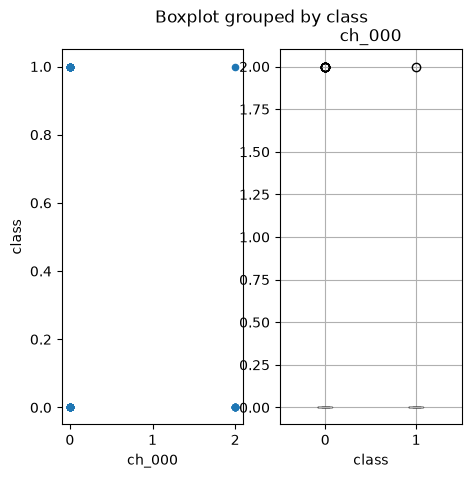

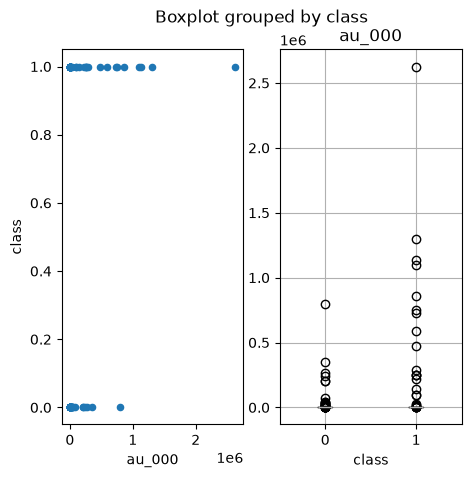

In [41]:
top= cv.nlargest(int(np.sqrt(170))).index
print("Top features per CV =",top)
for name in top:
    fig,(scatter_axis,box_axis)= subplots(ncols= 2,figsize= (5,5))
    train.plot.scatter(name,"class",ax= scatter_axis)
    train.boxplot(name,by= "class",ax= box_axis)

The 13 features with the highest CV are cf_000, co_000, ad_000, cs_009, dh_000, dj_000, ag_000, as_000, ay_009, ak_000, az_009, ch_000 and au_000. No, conclusions about significance cannot be drawn from the scatter plots. For both classes almost all points sit near 0, and a few extreme values stretch the axes, so the two classes cannot be told apart. The box plots show the same thing, with the boxes squeezed flat near 0 and the extreme values shown as outliers.

#### (v) Is this data set imbalanced?

In [7]:
print("Negative =",(train["class"]==0).sum())
print("Positive =",(train["class"]==1).sum())

Negative = 59000
Positive = 1000


The training set has 59000 negative and 1000 positive data points, so the data set is imbalanced. Only about 1.7% of the data is positive, a ratio of 59 to 1.

### (c) Train a random forest

In [8]:
y_train= train["class"]
x_test= test.drop(columns= "class")
y_test= test["class"]
forest= RandomForestClassifier(oob_score= True,random_state= 0).fit(x_train,y_train)

In [9]:
train_prediction= forest.predict(x_train)
test_prediction= forest.predict(x_test)
print(confusion_table(train_prediction,y_train))
print(confusion_table(test_prediction,y_test))
print("Training misclassification error =",np.mean(train_prediction!=y_train))
print("Test misclassification error =",np.mean(test_prediction!=y_test))

Truth          0     1
Predicted             
0          59000     0
1              0  1000
Truth          0    1
Predicted            
0          15610  103
1             15  272
Training misclassification error = 0.0
Test misclassification error = 0.007375


Training AUC = 1.0
Test AUC = 0.9943609173333335


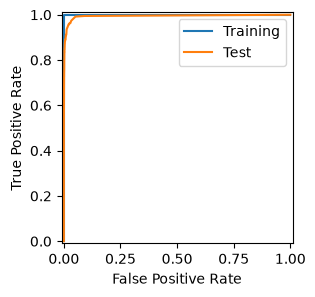

In [36]:
fig,axis= subplots(figsize= (3,3))
train_roc= RocCurveDisplay.from_estimator(forest,x_train,y_train,ax= axis)
test_roc= RocCurveDisplay.from_estimator(forest,x_test,y_test,ax= axis)
print("Training AUC =",train_roc.roc_auc)
print("Test AUC =",test_roc.roc_auc)
axis.legend(["Training","Test"])
axis.set_xlabel("False Positive Rate")
axis.set_ylabel("True Positive Rate");

In [11]:
print("OOB error =",1-forest.oob_score_)

OOB error = 0.006166666666666654


The training error is 0.0 because the forest fits the training data perfectly. The OOB error is 0.006166666666666654 and the test error is 0.007375. They are close, so the OOB error is a good estimate of the test error.

### (d) Research class imbalance in random forest

Common ways to handle class imbalance in random forests are class weights, balanced random forest, resampling the data and lowering the decision threshold for the positive class. Class weights give the minority class a larger weight. Balanced random forest undersamples the majority class in each bootstrap sample. Resampling oversamples the minority class, for example with SMOTE, or undersamples the majority class.

Class weights is the simplest because it is one setting in the forest and keeps all of the data, so it is applied here. The "balanced" setting was tried first, but it gave a warning that some inputs do not have OOB scores, which probably means too few trees were used to compute reliable OOB estimates. The "balanced_subsample" setting is used instead, which makes the weights inversely proportional to the class frequencies in each bootstrap sample.

In [12]:
balanced_forest= RandomForestClassifier(class_weight= "balanced_subsample",oob_score= True,random_state= 0).fit(x_train,y_train)

In [13]:
train_prediction= balanced_forest.predict(x_train)
test_prediction= balanced_forest.predict(x_test)
print(confusion_table(train_prediction,y_train))
print(confusion_table(test_prediction,y_test))
print("Training misclassification error =",np.mean(train_prediction!=y_train))
print("Test misclassification error =",np.mean(test_prediction!=y_test))

Truth          0     1
Predicted             
0          59000     0
1              0  1000
Truth          0    1
Predicted            
0          15609  156
1             16  219
Training misclassification error = 0.0
Test misclassification error = 0.01075


Training AUC = 1.0
Test AUC = 0.992173312


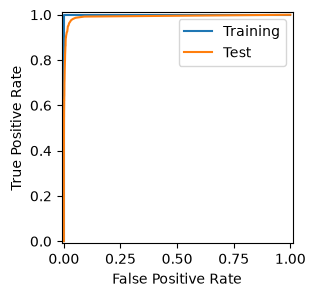

In [37]:
fig,axis= subplots(figsize= (3,3))
train_roc= RocCurveDisplay.from_estimator(balanced_forest,x_train,y_train,ax= axis)
test_roc= RocCurveDisplay.from_estimator(balanced_forest,x_test,y_test,ax= axis)
print("Training AUC =",train_roc.roc_auc)
print("Test AUC =",test_roc.roc_auc)
axis.legend(["Training","Test"])
axis.set_xlabel("False Positive Rate")
axis.set_ylabel("True Positive Rate");

In [15]:
print("OOB error =",1-balanced_forest.oob_score_)

OOB error = 0.007716666666666705


The test error went up from 0.007375 to 0.01075 and more positives were missed, 156 compared to 103. The OOB error also went up from 0.006166666666666654 to 0.007716666666666705, and it is now further below the test error than before. The class weights did not help here.

### (e) XGBoost and Model Trees

XGBoost was fit with an L1 penalty through reg_alpha, and nothing was done about the class imbalance here. Following the textbook lab, a grid of penalty values from 0.01 to 100 was tried, spaced evenly on a log scale, and 5-fold cross-validation picked the best one.

In [16]:
kfold= KFold(5,random_state= 0,shuffle= True)
alphas= 10**np.linspace(-2,2,5)
xgb_grid= GridSearchCV(XGBClassifier(random_state= 0),{"reg_alpha":alphas},cv= kfold).fit(x_train,y_train)
print("Best reg_alpha =",xgb_grid.best_params_["reg_alpha"])
print("CV error =",1-xgb_grid.best_score_)

Best reg_alpha = 0.01
CV error = 0.006433333333333402


In [17]:
train_prediction= xgb_grid.predict(x_train)
test_prediction= xgb_grid.predict(x_test)
print(confusion_table(train_prediction,y_train))
print(confusion_table(test_prediction,y_test))
print("Training misclassification error =",np.mean(train_prediction!=y_train))
print("Test misclassification error =",np.mean(test_prediction!=y_test))

Truth          0    1
Predicted            
0          59000    1
1              0  999
Truth          0    1
Predicted            
0          15609   86
1             16  289
Training misclassification error = 1.6666666666666667e-05
Test misclassification error = 0.006375


Training AUC = 0.9999999491525424
Test AUC = 0.9936580266666667


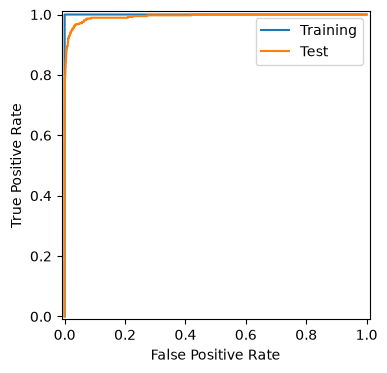

In [38]:
fig,axis= subplots(figsize= (4,4))
train_roc= RocCurveDisplay.from_estimator(xgb_grid,x_train,y_train,ax= axis)
test_roc= RocCurveDisplay.from_estimator(xgb_grid,x_test,y_test,ax= axis)
print("Training AUC =",train_roc.roc_auc)
print("Test AUC =",test_roc.roc_auc)
axis.legend(["Training","Test"])
axis.set_xlabel("False Positive Rate")
axis.set_ylabel("True Positive Rate");

The CV error is 0.006433333333333402 and the test error is 0.006375, so they agree closely. This is the lowest test error so far, and only 86 positives were missed.

### (f) Use SMOTE to pre-process your data

In [19]:
smote_pipeline= Pipeline(steps= [("smote",SMOTE(random_state= 0)),("xgb",XGBClassifier(random_state= 0))])
smote_grid= GridSearchCV(smote_pipeline,{"xgb__reg_alpha":alphas},cv= kfold).fit(x_train,y_train)
print("Best reg_alpha =",smote_grid.best_params_["xgb__reg_alpha"])
print("CV error =",1-smote_grid.best_score_)

Best reg_alpha = 0.1
CV error = 0.006616666666666715


In [20]:
train_prediction= smote_grid.predict(x_train)
test_prediction= smote_grid.predict(x_test)
print(confusion_table(train_prediction,y_train))
print(confusion_table(test_prediction,y_test))
print("Training misclassification error =",np.mean(train_prediction!=y_train))
print("Test misclassification error =",np.mean(test_prediction!=y_test))

Truth          0    1
Predicted            
0          59000    1
1              0  999
Truth          0    1
Predicted            
0          15538   55
1             87  320
Training misclassification error = 1.6666666666666667e-05
Test misclassification error = 0.008875


Training AUC = 0.9999930084745763
Test AUC = 0.9936155306666666


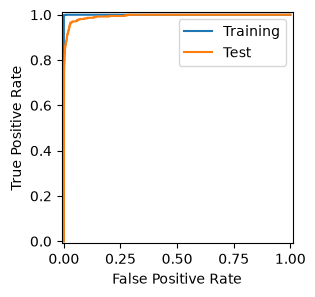

In [39]:
fig,axis= subplots(figsize= (3,3))
train_roc= RocCurveDisplay.from_estimator(smote_grid,x_train,y_train,ax= axis)
test_roc= RocCurveDisplay.from_estimator(smote_grid,x_test,y_test,ax= axis)
print("Training AUC =",train_roc.roc_auc)
print("Test AUC =",test_roc.roc_auc)
axis.legend(["Training","Test"])
axis.set_xlabel("False Positive Rate")
axis.set_ylabel("True Positive Rate");

SMOTE catches more of the positives, with 55 missed compared to 86, but it flags many more negatives as positive, 87 compared to 16. The test error goes up from 0.006375 to 0.008875, so SMOTE did not improve on plain XGBoost here.

## 2. ISLR 6.6.3

### (a) Training RSS
iv. Steadily decreases. At s = 0 all the coefficients are zero so the model just predicts the mean, and as s grows the coefficients fit the training data more and more until it reaches the least squares fit.

### (b) Test RSS
ii. It decreases initially and then eventually it starts to increase in a U shape. A small s has too high of a bias and a large s overfits the training data.

### (c) Variance
iii. Steadily increases. A larger s makes the model more flexible so the predictions change more depending on the training data.

### (d) Squared bias
iv. Steadily decreases. A more flexible model can match the true relationship better.

### (e) Irreducible error
v. Remains constant. It is the variance of the error term and it does not depend on s.

## 3. ISLR 6.6.5

### (a) Ridge regression
It minimizes the squared residuals plus a penalty on the squared coefficients.
$$\sum_{i=1}^{2}(y_i-\beta_1x_{i1}-\beta_2x_{i2})^2+\lambda(\beta_1^2+\beta_2^2)$$

### (b) Ridge coefficients
Setting the derivatives with respect to the two coefficients to zero and subtracting the equations leaves $2\lambda(\beta_1-\beta_2)=0$, because $x_{i1}=x_{i2}$. So the ridge estimates are equal.
$$\hat\beta_1=\hat\beta_2$$

### (c) Lasso
It is the same as ridge but the penalty is on the absolute values.
$$\sum_{i=1}^{2}(y_i-\beta_1x_{i1}-\beta_2x_{i2})^2+\lambda(|\beta_1|+|\beta_2|)$$

### (d) Lasso coefficients
Since $x_{i1}=x_{i2}$ the fit only depends on $\beta_1+\beta_2$, so any pair on the edge of the constraint $|\beta_1|+|\beta_2|\le s$ with the same sign works. That means the lasso solution is not unique.
$$\hat\beta_1+\hat\beta_2=s\ \text{with}\ \hat\beta_1,\hat\beta_2\ge0$$
$$\hat\beta_1+\hat\beta_2=-s\ \text{with}\ \hat\beta_1,\hat\beta_2\le0$$

## 4. ISLR 8.4.5

Majority vote: each tree votes Red if its probability is above 0.5 and Green otherwise. Red gets 6 votes from 0.55, 0.6, 0.6, 0.65, 0.7 and 0.75, and Green gets 4 votes from 0.1, 0.15, 0.2 and 0.2. Red gets more votes, so the final prediction is Red.

Average probability: add up all 10 probabilities and divide by 10. The average is 0.45, which is below 0.5, so the final prediction is Green.

The two methods disagree. Majority vote only counts which side of 0.5 each tree lands on, while the average also looks at how sure each tree is. The four Green trees are very sure, but the six Red trees are only a little above 0.5.

## 5. ISLR 9.7.3

### Part a


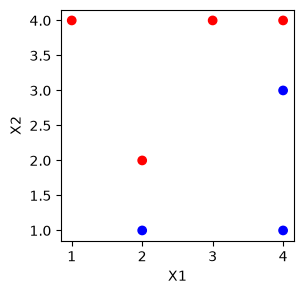

In [22]:
x1= np.array([3,2,4,1,2,4,4])
x2= np.array([4,2,4,4,1,3,1])
color= ["red","red","red","red","blue","blue","blue"]
fig,axis= subplots(figsize= (3,3))
axis.scatter(x1,x2,c= color)
axis.set_xlabel("X1")
axis.set_ylabel("X2");

### Part b

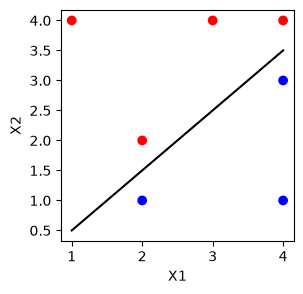

In [23]:
fig,axis= subplots(figsize= (3,3))
axis.scatter(x1,x2,c= color)
axis.plot([1,4],[0.5,3.5],color= "black")
axis.set_xlabel("X1")
axis.set_ylabel("X2");

### Part b
The hyperplane goes through the midpoints of obs 2 and 5 and of obs 3 and 6, which are $(2,1.5)$ and $(4,3.5)$. The slope is 1, so it is $X_2=X_1-0.5$.
$$0.5-X_1+X_2=0$$

### Part c
It classifies to Red if $0.5-X_1+X_2>0$ and if not it is Blue.
$$\beta_0=0.5\qquad\beta_1=-1\qquad\beta_2=1$$

### Part d
The margin is the distance from the closest points to the hyperplane.
$$\text{margin}=\frac{0.5}{\sqrt2}\approx0.354$$

### Part e
The support vectors are observations 2, 3, 5 and 6, because they sit exactly on the margin.

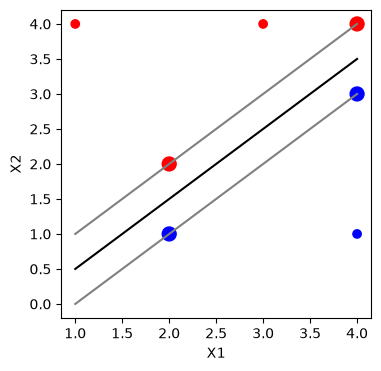

In [24]:
fig,axis= subplots(figsize= (4,4))
axis.scatter(x1,x2,c= color)
axis.plot([1,4],[0.5,3.5],color= "black")
axis.plot([1,4],[1,4],color= "gray")
axis.plot([1,4],[0,3],color= "gray")
axis.scatter([2,4,2,4],[2,4,1,3],c= ["red","red","blue","blue"],s= 100)
axis.set_xlabel("X1")
axis.set_ylabel("X2");

### Part f
Observation 7 is about 1.768 from the hyperplane, far outside the margin, so it is not a support vector and moving it a little does not change the hyperplane.


### Part g
$$0.3-X_1+X_2=0$$

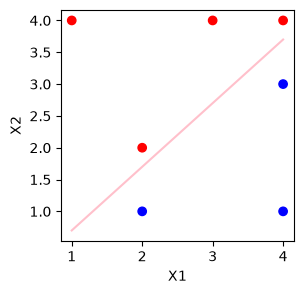

In [25]:
fig,axis= subplots(figsize= (3,3))
axis.scatter(x1,x2,c= color)
axis.plot([1,4],[0.7,3.7],color= "pink")
axis.set_xlabel("X1")
axis.set_ylabel("X2");

### Part h
There is an extra Blue observation at $(X_1,X_2)=(2,3)$. It sits inside the group of Red observations, so the two classes can no longer be separated by a hyperplane

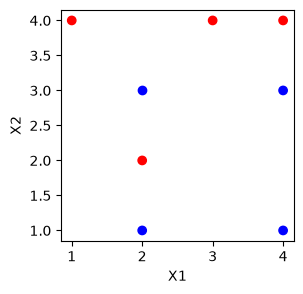

In [26]:
fig,axis= subplots(figsize= (3,3))
axis.scatter(x1,x2,c= color)
axis.scatter(2,3,c= "blue")
axis.set_xlabel("X1")
axis.set_ylabel("X2");